<a href="https://colab.research.google.com/github/asegura4488/EDCO_IntroCienciaDatos/blob/main/Semana6/RedNeuronal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:


from google.colab import drive
from google.colab import files
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
import os
os.chdir('/content/drive/MyDrive/EDCO_IntroCienciaDatos/Semana6')
!ls

AccionApple.ipynb		 Datos	  RedNeuronal.ipynb
Analisis_precio_dolar_TRM.ipynb  figuras


In [3]:

# Paquetes básicos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Paquetes de ML
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler # Muy importante cuando usamos redes - aprendizaje profundo
from sklearn.metrics import roc_curve, roc_auc_score, classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.metrics import AUC as KerasAUC

In [10]:

df = pd.read_csv('Datos/Churn_Modelling.csv')
df

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [11]:
for col in ['RowNumber', 'CustomerId', 'Surname']:
  df.drop( col, axis=1, inplace=True )

In [12]:
df

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...
9995,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


# Objetivo:
## Queremos predecir si el cliente mantiene o no el producto

In [13]:
y = df['Exited'].astype(int)
x = df.drop(columns='Exited')

In [15]:
x

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,619,France,Female,42,2,0.00,1,1,1,101348.88
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58
2,502,France,Female,42,8,159660.80,3,1,0,113931.57
3,699,France,Female,39,1,0.00,2,0,0,93826.63
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10
...,...,...,...,...,...,...,...,...,...,...
9995,771,France,Male,39,5,0.00,2,1,0,96270.64
9996,516,France,Male,35,10,57369.61,1,1,1,101699.77
9997,709,France,Female,36,7,0.00,1,0,1,42085.58
9998,772,Germany,Male,42,3,75075.31,2,1,0,92888.52


In [17]:
# Que hacemos con las variables categoricas:
# Codificación one-hot encoding
X = pd.get_dummies(x, drop_first=True)
X

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...
9995,771,39,5,0.00,2,1,0,96270.64,False,False,True
9996,516,35,10,57369.61,1,1,1,101699.77,False,False,True
9997,709,36,7,0.00,1,0,1,42085.58,False,False,False
9998,772,42,3,75075.31,2,1,0,92888.52,True,False,True


<Axes: ylabel='Frequency'>

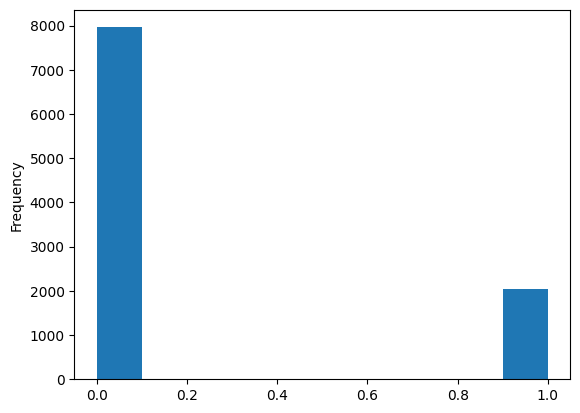

In [19]:
# Vamos mirar la variable a predecir
# UN problema de clasificacion desbalanceado
y.plot(kind='hist')

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,stratify=y)

In [24]:
# Vamos a Balancear la data
train = X_train.copy()
train['Exited'] = y_train.values

clase0 = train[ train['Exited'] == 0 ]
clase1 = train[ train['Exited'] == 1 ]

n_min = len(clase1)
n_min

1630

In [25]:
# Es la cantidad minimima de datos que necesito de la clase 0
clase_down = clase0.sample( n = n_min, random_state=42 )

In [27]:
train_bal = pd.concat( [clase_down, clase1] )

In [28]:
y_train = train_bal['Exited'].astype(int)
X_train = train_bal.drop(columns='Exited')

(array([1630.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
        1630.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

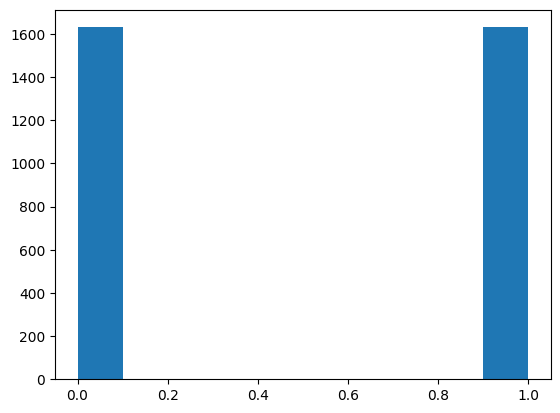

In [30]:
plt.hist(y_train.values)

In [85]:
# Vamos escalar los datos, inevitable
scaler = StandardScaler()
scaler.fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

In [86]:
# Estamos listos
model = Sequential([
    Dense(20, activation='relu', input_dim=X_train_s.shape[1]), # Debe estar la dimension de espacio columna
    Dropout(0.3),
    Dense(50, activation='relu'),
    Dropout(0.3),
    Dense(5, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid') # Salida es una sola neurona
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [87]:
# Compilamos la red
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', KerasAUC(name='auc')]
)
model

<Sequential name=sequential_9, built=True>

In [88]:
# Early stopping
es = EarlyStopping(monitor='val_loss', patience=10, verbose=1, restore_best_weights=True)
history = model.fit(
    X_train_s,
    y_train,
    validation_split=0.2,
    epochs=200,
    batch_size=32,
    callbacks=[es],
    verbose=1
)

Epoch 1/200
82/82 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.5621 - auc: 0.5321 - loss: 0.6894 - val_accuracy: 0.0537 - val_auc: 0.0000e+00 - val_loss: 0.8305
Epoch 2/200
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6085 - auc: 0.5822 - loss: 0.6541 - val_accuracy: 0.0215 - val_auc: 0.0000e+00 - val_loss: 0.8666
Epoch 3/200
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6331 - auc: 0.6342 - loss: 0.6356 - val_accuracy: 0.0613 - val_auc: 0.0000e+00 - val_loss: 0.8477
Epoch 4/200
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6449 - auc: 0.6710 - loss: 0.6189 - val_accuracy: 0.2239 - val_auc: 0.0000e+00 - val_loss: 0.8791
Epoch 5/200
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6549 - auc: 0.6994 - loss: 0.6025 - val_accuracy: 0.3543 - val_auc: 0.0000e+00 - val_loss: 0.8661
Epoch 6/200
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6860 - auc: 0.7202 - loss: 0.5950 - val_accuracy: 0.4739 - val_auc: 0.0000e+00 - val_loss: 0.8139
Epoch 7/200
82/82 ━━━

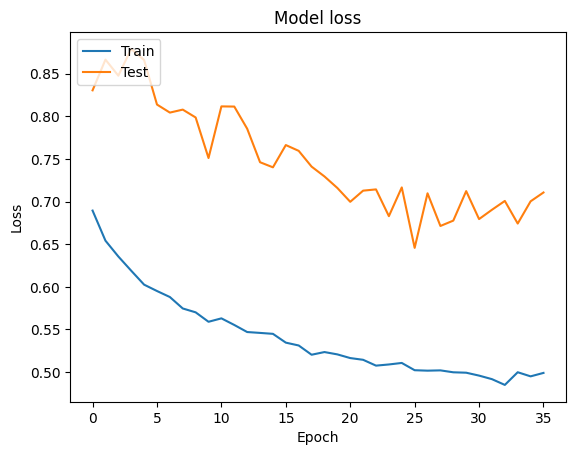

In [90]:
plt.figure()
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

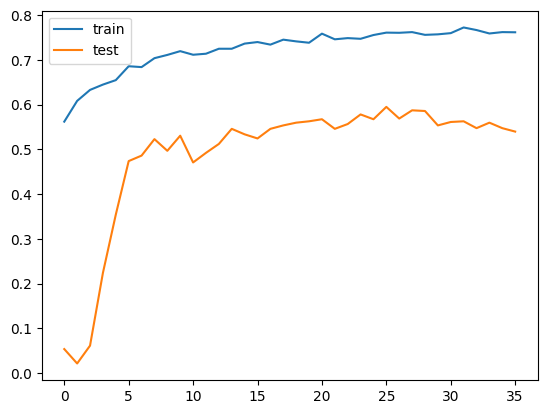

In [91]:

if 'accuracy' in history.history and 'val_accuracy' in history.history:
##  print('dfd')
    plt.figure()
    plt.plot(history.history['accuracy'],label='train')
    plt.plot(history.history['val_accuracy'],label='test')
    plt.legend()

In [92]:
# Predecir
y_prob = model.predict(X_test_s).ravel()
y_prob

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


array([0.4799387 , 0.06437197, 0.06980918, ..., 0.57794964, 0.54823494,
       0.37602133], dtype=float32)

In [93]:
test_auc = roc_auc_score(y_test, y_prob)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
print(test_auc)

0.8202007863024813


Text(0, 0.5, 'True Positive Rate')

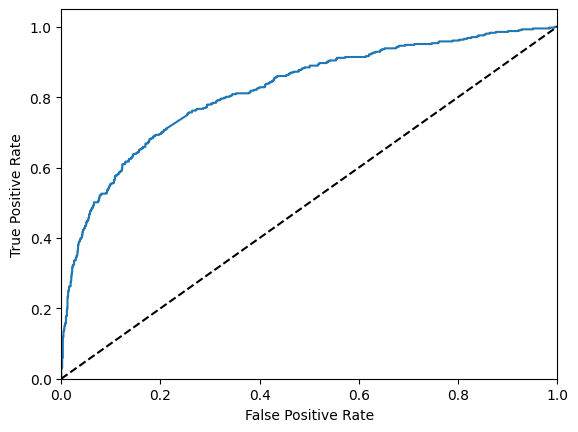

In [94]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = %0.2f)' % test_auc)
plt.plot([0,1], [0,1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')